# B. Klaster ritme harian kapanewon di DIY

**Pertanyaan:** Kapanewon mana yang punya profil kehadiran perangkat per jam yang mirip pada hari kerja?

**Periode:** 1 Desember 2021–28 Februari 2022, dengan 61 hari kerja biasa mengikuti notebook A.

**Masukan:**
- `data/processed/A_ritme_kapanewon.csv` dari [notebook A](A_ritme_harian.ipynb), bersumber dari [JogjaPulse](https://zenodo.org/records/23157460). Kolom `idx_kerja_h0` sampai `idx_kerja_h23` adalah rata-rata indeks per jam pada hari kerja. Bagian A membagi hitungan per jam dengan rata-rata harian masing-masing kapanewon, mengecualikan tanggal anomali dan hari libur, mengisi slot yang tersupresi dengan 2,5, dan menutup jam gangguan pengiriman data.
- `data/external/batas_kapanewon.geojson` dari [Geoportal DIY](https://geoportal.jogjaprov.go.id/server/rest/services/ADMIN_BATASWILAYAH/DIY_34_ADMINISTRASIKEC_AR/FeatureServer/0). Peta digabung lewat kode BPS `kdcbps`. Tahun geometri belum terkonfirmasi.

Setiap kapanewon punya bobot yang sama. K-means memakai 24 indeks dalam skala yang sama dengan jarak Euclidean. Indeks 1 berarti setara rata-rata harian. Kami memakai indeks dari A langsung agar setiap selisih indeks punya satuan yang sama di semua jam.

In [1]:
from pathlib import Path
import sys

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ritme" / "io.py").is_file()),
    None,
)
if root is None:
    raise RuntimeError("Buka notebook dari folder ritme-jogja atau notebooks/.")
sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from threadpoolctl import threadpool_limits

from ritme import io, maps, style

style.apply()

JAM = list(range(24))
FITUR = [f"idx_kerja_h{jam}" for jam in JAM]
AMBANG_SUPRESI = 0.20
KANDIDAT_K = range(2, 7)
SEED = 42
N_INIT = 50
KODE = "kapanewon_code"

csv_path = io.PROCESSED_DIR / "A_ritme_kapanewon.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"{csv_path} belum ada. Jalankan notebook A atau pakai CSV hasil A dari tim.")

data = pd.read_csv(csv_path, dtype={KODE: "string", "kab_code": "string"})
data = data.sort_values(KODE).reset_index(drop=True)
X = data[FITUR].to_numpy(dtype=float)
proporsi = data["prop_jam_terisi"]
if len(data) != 78 or data[KODE].isna().any() or not data[KODE].is_unique:
    raise ValueError("Masukan harus berisi 78 kode kapanewon yang terisi dan unik.")
if not np.isfinite(X).all():
    raise ValueError("Semua 24 indeks jam harus berisi angka hingga.")
if not proporsi.between(0, 1).all():
    raise ValueError("Proporsi slot yang diisi harus berada antara 0 dan 1.")

data["supresi_tinggi"] = proporsi > AMBANG_SUPRESI
print(f"{len(data)} kapanewon × {len(FITUR)} jam; "
      f"{data['supresi_tinggi'].sum()} kapanewon melewati ambang 20% slot yang diisi.")

78 kapanewon × 24 jam; 9 kapanewon melewati ambang 20% slot yang diisi.


## K-means pada 24 indeks jam

Kami mencoba 50 titik awal untuk setiap nilai k dengan seed 42. Inertia dipakai untuk melihat tambahan kecocokan dan silhouette untuk membandingkan pemisahan klaster.

In [2]:
def fit_kmeans(profil, k):
    # Satu thread cukup untuk matriks kecil ini dan menghindari oversubscription.
    with threadpool_limits(limits=1):
        return KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(profil)


model_per_k = {k: fit_kmeans(X, k) for k in KANDIDAT_K}
evaluasi = pd.DataFrame([
    {
        "k": k,
        "inertia": m.inertia_,
        "silhouette": silhouette_score(X, m.labels_),
        "ukuran_klaster": ", ".join(map(str, sorted(np.bincount(m.labels_), reverse=True))),
    }
    for k, m in model_per_k.items()
]).set_index("k")

evaluasi.round(3)

,inertia,silhouette,ukuran_klaster
k,,,
2,11.307,0.584,"75, 3"
3,8.693,0.230,"39, 36, 3"
4,7.388,0.203,"26, 26, 23, 3"
5,6.093,0.213,"26, 26, 23, 2, 1"
6,5.391,0.222,"25, 24, 22, 4, 2, 1"


## Pemilihan jumlah klaster

Kami membandingkan k = 2–6. Inertia mengukur jumlah kuadrat jarak ke centroid dan akan turun ketika k bertambah. Silhouette mendekati 1 ketika profil lebih dekat dengan kelompoknya sendiri dibandingkan dengan kelompok lain.

**Kami memilih k = 3 untuk peta seluruh DIY.** Pada k = 2, silhouette tertinggi (0,584) berasal dari pembagian 75–3: satu klaster besar berisi dua pola jam puncak, sedangkan tiga profil menyimpang berada di klaster kecil. Dengan k = 3, klaster besar terbelah menjadi pola puncak siang (36) dan petang (39). Tiga profil tadi masih terpisah. Nilai k = 4–6 menambah klaster dengan silhouette yang lebih rendah daripada k = 3.

Silhouette k = 3 sebesar 0,230 menunjukkan tumpang tindih antarkelompok. Klaster dipakai untuk merangkum pola aktivitas teramati. Fungsi wilayah seperti hunian, pusat kegiatan, atau wisata memerlukan data pendukung tersendiri.

Rujukan metode: [K-means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) dan [silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

In [3]:
PILIH_K = 3
model = model_per_k[PILIH_K]
centroid = model.cluster_centers_
ukuran = np.bincount(model.labels_)
id_tak_lazim = int(ukuran.argmin())
id_lain = sorted(
    (i for i in range(PILIH_K) if i != id_tak_lazim),
    key=lambda i: centroid[i].argmax(),
)
urutan = [*id_lain, id_tak_lazim]
nama = {
    id_lain[0]: "Puncak siang",
    id_lain[1]: "Puncak petang",
    id_tak_lazim: "Profil tak lazim",
}
warna = dict(zip(urutan, style.CATEGORICAL[:3]))
garis = dict(zip(urutan, ["-", "--", ":"]))

hasil = data[[KODE, "kab_code", "kab_kota", "kapanewon", "prop_jam_terisi", "supresi_tinggi"]].copy()
hasil["klaster"] = pd.Categorical([nama[i] for i in model.labels_], [nama[i] for i in urutan], ordered=True)
hasil["jam_puncak"] = X.argmax(axis=1)
hasil["jarak_centroid"] = np.linalg.norm(X - centroid[model.labels_], axis=1)
hasil["silhouette_individu"] = silhouette_samples(X, model.labels_)

ringkasan = pd.DataFrame([
    {
        "klaster": nama[i],
        "n_kapanewon": ukuran[i],
        "puncak_centroid_wib": f"{centroid[i].argmax():02d}.00",
        "indeks_puncak": centroid[i].max(),
        "n_supresi_tinggi": hasil.loc[model.labels_ == i, "supresi_tinggi"].sum(),
        "contoh_dekat_centroid": ", ".join(
            hasil.loc[model.labels_ == i].nsmallest(2, "jarak_centroid")["kapanewon"].str.title()
        ),
    }
    for i in urutan
]).set_index("klaster")
display(ringkasan.round(2))
display(pd.crosstab(hasil["kab_kota"], hasil["klaster"]).reindex(style.KAB_ORDER))
display(hasil.loc[model.labels_ == id_tak_lazim, [
    "kapanewon", "kab_kota", "jam_puncak", "prop_jam_terisi", "silhouette_individu"
]].round(3))

,n_kapanewon,puncak_centroid_wib,indeks_puncak,n_supresi_tinggi,contoh_dekat_centroid
klaster,,,,,
Puncak siang,36,12.00,1.44,6,"Pengasih, Temon"
Puncak petang,39,19.00,1.41,1,"Kalasan, Sedayu"
Profil tak lazim,3,12.00,1.43,2,"Girisubo, Rongkop"


klaster,Puncak siang,Puncak petang,Profil tak lazim
kab_kota,,,
YOGYAKARTA,6,7,1
SLEMAN,4,13,0
BANTUL,3,14,0
KULON PROGO,8,4,0
GUNUNGKIDUL,15,1,2


,kapanewon,kab_kota,jam_puncak,prop_jam_terisi,silhouette_individu
39,RONGKOP,GUNUNGKIDUL,12,0.536,-0.097
44,GIRISUBO,GUNUNGKIDUL,20,0.664,0.101
73,GONDOMANAN,YOGYAKARTA,12,0.000,0.066


## Uji sensitivitas terhadap cakupan dan profil tak lazim

Ambang 20% mengikuti penanda kualitas di notebook A. Angka itu adalah proporsi slot yang diisi pada periode utama sebagaimana dihitung oleh A. Kami melatih ulang K-means pada wilayah yang tersisa dan membandingkan label hanya pada wilayah itu. Untuk varian tanpa kelompok tak lazim, kami menguji ulang dua pola utama dengan k = 2. Adjusted Rand Index (ARI) membandingkan pembagian anggota dan bernilai 1 bila pembagiannya sama. Hitungan anggota yang sama memakai penyelarasan label yang memaksimalkan kecocokan.

In [4]:
def bandingkan_klaster(label, pilih, k):
    acuan = model.labels_[pilih]
    variasi = fit_kmeans(X[pilih], k).labels_
    # Nama/nomor klaster internal dapat bertukar ketika model dilatih ulang.
    tabel = pd.crosstab(acuan, variasi).to_numpy()
    baris, kolom = linear_sum_assignment(-tabel)
    return {
        "varian": label,
        "n_dibandingkan": int(pilih.sum()),
        "k_refit": k,
        "jumlah_sama": int(tabel[baris, kolom].sum()),
        "ARI": adjusted_rand_score(acuan, variasi),
    }


supresi_rendah = ~hasil["supresi_tinggi"]
gondomanan = hasil["kapanewon"].eq("GONDOMANAN") & hasil["kab_kota"].eq("YOGYAKARTA")
if gondomanan.sum() != 1:
    raise ValueError("Gondomanan tidak ditemukan secara unik pada data A.")
bukan_gondomanan = ~gondomanan

sensitivitas = pd.DataFrame([
    bandingkan_klaster("Keluarkan 9 wilayah dengan >20% slot diisi", supresi_rendah, 3),
    bandingkan_klaster("Keluarkan Gondomanan", bukan_gondomanan, 3),
    bandingkan_klaster("Keluarkan klaster profil tak lazim", model.labels_ != id_tak_lazim, 2),
    bandingkan_klaster("Keluarkan wilayah supresi tinggi dan Gondomanan", supresi_rendah & bukan_gondomanan, 2),
]).set_index("varian")
sensitivitas.round(3)

,n_dibandingkan,k_refit,jumlah_sama,ARI
varian,,,,
Keluarkan 9 wilayah dengan >20% slot diisi,69,3,69,1.000
Keluarkan Gondomanan,77,3,77,1.000
Keluarkan klaster profil tak lazim,75,2,73,0.895
Keluarkan wilayah supresi tinggi dan Gondomanan,68,2,68,1.000


## Grafik profil rata-rata klaster

Garis adalah centroid K-means, yaitu rata-rata indeks dari semua anggota klaster pada setiap jam. Titik menandai jam puncak centroid dua klaster utama.

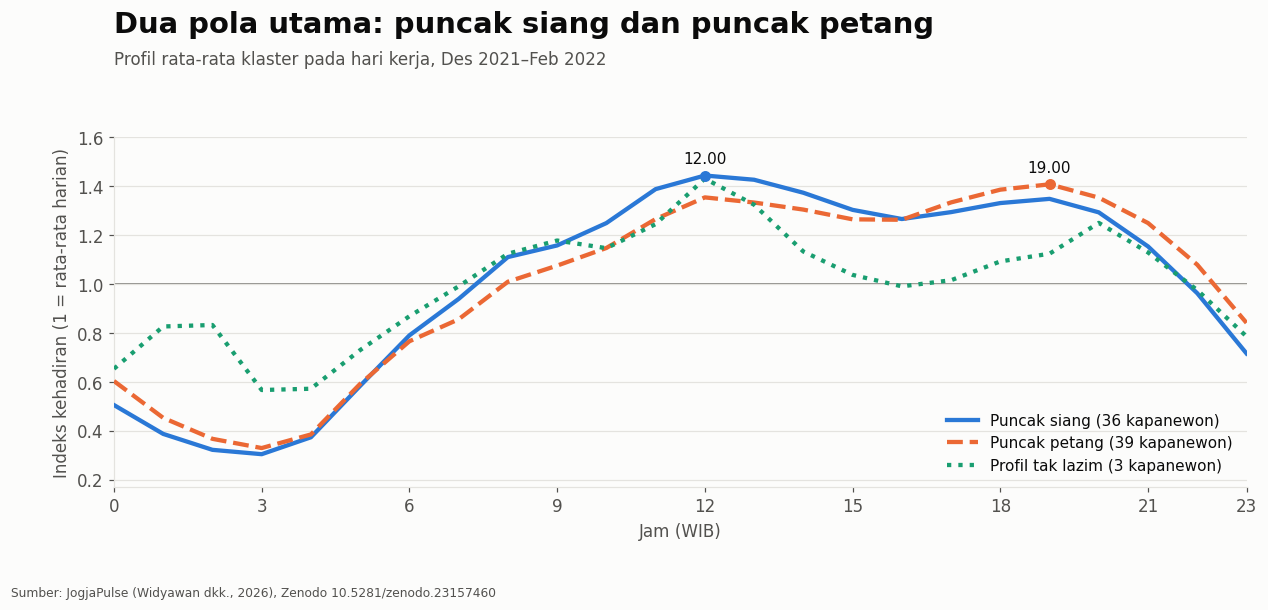

In [5]:
fig, ax = plt.subplots(figsize=(11.7, 5.3))
fig.subplots_adjust(left=0.09, right=0.97, top=0.76, bottom=0.16)
fig.text(0.09, 0.94, "Dua pola utama: puncak siang dan puncak petang",
         fontsize=19, fontweight="bold")
fig.text(0.09, 0.885, "Profil rata-rata klaster pada hari kerja, Des 2021–Feb 2022",
         color=style.TEXT_SECONDARY)

ax.axhline(1, linewidth=1.2, color=style.EVENT_LINE, zorder=1)
for i in urutan:
    y = centroid[i]
    ax.plot(JAM, y, color=warna[i], linestyle=garis[i], linewidth=2.8,
            label=f"{nama[i]} ({ukuran[i]} kapanewon)", zorder=3)
    if i != id_tak_lazim:
        jam_puncak = int(y.argmax())
        ax.scatter(jam_puncak, y[jam_puncak], color=warna[i], s=38, zorder=4)
        ax.annotate(f"{jam_puncak:02d}.00", (jam_puncak, y[jam_puncak]),
                    xytext=(0, 8), textcoords="offset points", ha="center",
                    color=style.TEXT_PRIMARY, fontsize=10)

ax.set(xlim=(0, 23), ylim=(0.17, 1.6), xticks=[0, 3, 6, 9, 12, 15, 18, 21, 23],
       xlabel="Jam (WIB)", ylabel="Indeks kehadiran (1 = rata-rata harian)")
ax.legend(loc="lower right", fontsize=10)
style.add_source(fig)
style.save(fig, "B1_profil_klaster")
plt.show()

## Peta klaster kapanewon

Gabungkan hasil ke batas wilayah DIY berdasarkan kode BPS. Lingkaran putih menandai kapanewon dengan lebih dari 20% slot diisi. Kotak putus-putus menandai cakupan pembesaran sekitar Kota Yogyakarta.

78 kode cocok; 78 geometri valid pada peta.


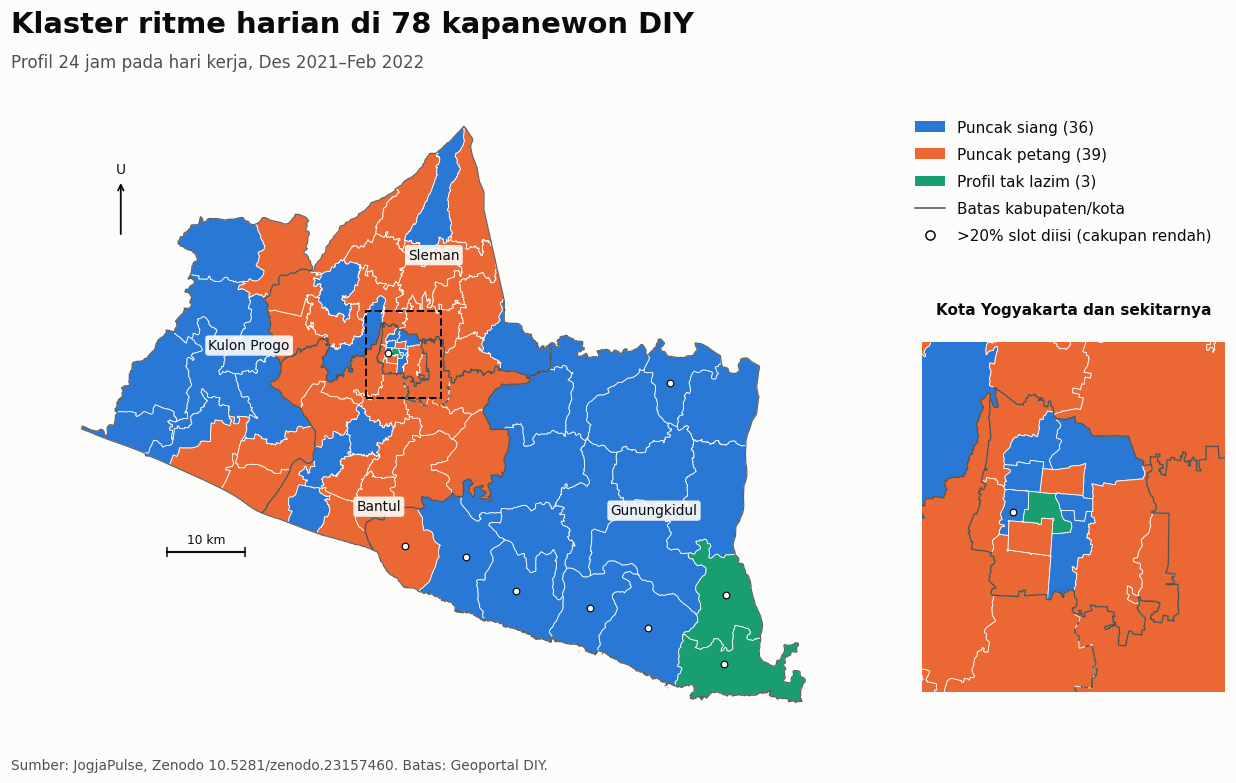

In [6]:
batas = maps.load_kapanewon_boundaries()
if set(batas[KODE]) != set(hasil[KODE]):
    raise ValueError("Set kode BPS di GeoJSON dan CSV A harus sama untuk peta klaster.")
if not batas.geometry.is_valid.all():
    raise ValueError("Ada poligon batas wilayah yang tidak valid.")

peta = maps.join_kapanewon_boundaries(hasil, boundaries=batas).to_crs(epsg=32749)
if len(peta) != len(hasil) or peta["klaster"].isna().any():
    raise ValueError("Semua 78 kapanewon harus mendapat satu klaster di peta.")
print(f"{len(peta)} kode cocok; {peta.geometry.is_valid.sum()} geometri valid pada peta.")

batas_kab = peta.dissolve(by="wadmkk").boundary
titik = peta.geometry.representative_point()
id_warna = peta["klaster"].map({nama[i]: warna[i] for i in urutan})


def gambar_poligon(ax):
    peta.plot(ax=ax, color=id_warna, edgecolor=style.SURFACE, linewidth=0.55)
    batas_kab.plot(ax=ax, color=style.TEXT_SECONDARY, linewidth=0.8, alpha=0.90)
    titik.loc[peta["supresi_tinggi"]].plot(
        ax=ax, facecolor=style.SURFACE, edgecolor=style.TEXT_PRIMARY,
        markersize=19, linewidth=0.8, zorder=4,
    )
    ax.axis("off")


fig = plt.figure(figsize=(12, 7.4))
fig.text(0.04, 0.94, "Klaster ritme harian di 78 kapanewon DIY",
         fontsize=19, fontweight="bold")
fig.text(0.04, 0.897, "Profil 24 jam pada hari kerja, Des 2021–Feb 2022",
         color=style.TEXT_SECONDARY)
ax = fig.add_axes([0.035, 0.08, 0.665, 0.78])
gambar_poligon(ax)
detail = fig.add_axes([0.73, 0.13, 0.23, 0.43])
gambar_poligon(detail)

# Perbesar Kota Yogyakarta dan kapanewon di sekitarnya.
xmin, ymin, xmax, ymax = peta.loc[peta["kab_kota"].eq("YOGYAKARTA")].total_bounds
pad = 1450
kiri, bawah, kanan, atas = xmin - pad, ymin - pad, xmax + pad, ymax + pad
detail.set(xlim=(kiri, kanan), ylim=(bawah, atas))
detail.set_title("Kota Yogyakarta dan sekitarnya", fontsize=10, loc="center")
ax.add_patch(Rectangle(
    (kiri, bawah), kanan - kiri, atas - bawah, fill=False,
    edgecolor=style.TEXT_PRIMARY, linestyle="--", linewidth=1.3, zorder=5,
))
# Letak label digeser sedikit agar poligon kecil dan penanda supresi tetap terlihat.
for label, easting, northing in [
    ("Kulon Progo", 411500, 9138500),
    ("Sleman", 435000, 9150000),
    ("Bantul", 428000, 9118000),
    ("Gunungkidul", 463000, 9117500),
]:
    ax.text(easting, northing, label, ha="center", va="center", fontsize=9, zorder=6,
            bbox={"boxstyle": "round,pad=0.23", "fc": style.SURFACE, "ec": "none", "alpha": 0.9})

# Peta memakai koordinat UTM dalam meter.
bar_x, bar_y = 401000, 9112300
ax.plot([bar_x, bar_x + 10_000], [bar_y, bar_y], color=style.TEXT_PRIMARY,
        linewidth=1.4, marker="|", markersize=7, zorder=6)
ax.text(bar_x + 5000, bar_y + 1100, "10 km", ha="center", fontsize=8)
ax.annotate("U", xy=(0.095, 0.78), xytext=(0.095, 0.875),
            xycoords="axes fraction", textcoords="axes fraction",
            ha="center", va="bottom", fontsize=9,
            arrowprops={"arrowstyle": "<-", "color": style.TEXT_PRIMARY, "linewidth": 1.2})

handles = [Patch(facecolor=warna[i], label=f"{nama[i]} ({ukuran[i]})") for i in urutan]
handles.extend([
    Line2D([], [], color=style.TEXT_SECONDARY, linewidth=1, label="Batas kabupaten/kota"),
    Line2D([], [], linestyle="none", marker="o", markerfacecolor=style.SURFACE,
           markeredgecolor=style.TEXT_PRIMARY, label=">20% slot diisi (cakupan rendah)"),
])
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.72, 0.84),
           borderaxespad=0, fontsize=10, labelspacing=0.8)
fig.text(0.04, 0.035, "Sumber: JogjaPulse, Zenodo 10.5281/zenodo.23157460. Batas: Geoportal DIY.",
         fontsize=9, color=style.TEXT_SECONDARY)
style.save(fig, "B2_peta_klaster")
plt.show()

In [7]:
out = io.PROCESSED_DIR / "B_klaster_kapanewon.csv"
hasil.to_csv(out, index=False)
print(f"{len(hasil)} baris disimpan ke {out.relative_to(io.ROOT)}")

78 baris disimpan ke data\processed\B_klaster_kapanewon.csv


## Temuan dan batas pembacaan

- **Puncak siang dan petang.** Centroid puncak siang mencapai indeks 1,44 pukul 12.00 WIB (36 kapanewon). Centroid puncak petang mencapai 1,41 pukul 19.00 WIB (39 kapanewon). Kedua pola teramati paling rendah pukul 03.00. Pengasih dan Temon paling dekat dengan profil rata-rata puncak siang. Kalasan dan Sedayu paling dekat dengan profil puncak petang.
- **Sebaran berbeda per kabupaten.** Puncak petang mencakup 14 dari 17 kapanewon di Bantul dan 13 dari 17 di Sleman. Puncak siang mencakup 15 dari 18 di Gunungkidul. Kota Yogyakarta mempunyai anggota dari kedua pola utama, dengan 6 puncak siang dan 7 puncak petang.
- **Tiga profil tak lazim.** Girisubo dan Rongkop masing-masing memiliki sekitar 66% dan 54% slot yang diisi. Gondomanan mempunyai lonjakan indeks pada pukul 01.00–02.00. Bagian A mencatat bahwa lonjakan itu membesar setelah perubahan sampel. Ketiga wilayah tersebut perlu dibaca secara terpisah sebelum menarik tafsir tentang fungsi kawasan.

Saat sembilan wilayah bercakupan rendah dan Gondomanan dikeluarkan, model dua klaster menempatkan **68 dari 68** kapanewon pada kelompok utama yang sama (ARI 1,00). Saat hanya klaster tiga profil tak lazim yang dikeluarkan, **73 dari 75** penempatan tetap sama (ARI 0,895). Uji ini memeriksa dampak pemilihan wilayah. Pengujian nilai isian yang berbeda memerlukan data mentah atau ekspor ulang profil dari A.

Indeks mengukur kehadiran perangkat yang mengirim ping. Jumlah perangkat teramati dan cakupan slot dapat berubah. Hasil menggambarkan hari kerja dalam periode kajian, sehingga tidak langsung berlaku untuk akhir pekan, hari libur, atau penggunaan lahan.